# Country and immigrant status: should we add them?

*Ahmed. Uses the clean table and folds from `02_data-analysis`.*

The team left two decisions open: whether to use the system (`CNT`) as a predictor, and whether to add immigrant status (`IMMIG`) as an 18th predictor. Here we add country, immigrant status, or both to the 17 predictors, rerun gradient boosting with the settings picked in `ahmed_gradient_boosting.ipynb`, and measure the gain against the 17-predictor model on the same plausible values and school folds. Then we try a fairer flag inside each system, since the main notebook found the 0.5 cut-off lopsided there. The main models stay on the 17 predictors either way, so they still compare with the teammates' models.

| Reads | Writes |
|---|---|
| `../data/clean/pisa6_clean.parquet` | `outputs/ahmed_extra_predictors.csv` |
| `../data/clean/columns.json` | `outputs/ahmed_flag_by_system.csv` |
| `../data/clean/folds.csv` | `outputs/figures/ahmed_extra_predictors.png` |
| `outputs/ahmed_hgb_params.json` | `outputs/figures/ahmed_flag_by_system.png` |
| `outputs/ahmed_hgb_results.csv` | |

# 1) Setup and data

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (roc_auc_score, average_precision_score, balanced_accuracy_score, recall_score,
                             root_mean_squared_error, r2_score)

DATA = Path("../data")
OUT = Path("outputs")
FIGS = OUT / "figures"
df = pd.read_parquet(DATA / "clean/pisa6_clean.parquet")
roles = json.loads((DATA / "clean/columns.json").read_text(encoding="utf-8"))
folds = pd.read_csv(DATA / "clean/folds.csv")
df["fold"] = df["CNTSCHID"].map(folds.set_index("CNTSCHID")["fold"])
GROUPS = roles["feature_groups"]
FEATURES = [c for cols in GROUPS.values() for c in cols]
PVS = range(1, 11)
SYSTEMS = ["ARE", "SAU", "QAT", "JOR", "MAR", "PSE"]
w = df["SENWT"] / df["SENWT"].mean()
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

best = json.loads((OUT / "ahmed_hgb_params.json").read_text(encoding="utf-8"))
saved = pd.read_csv(OUT / "ahmed_hgb_results.csv")

assert not any(c.startswith("PV") or "READ" in c or "SCIE" in c for c in FEATURES)

IMMIG_NAMES = {1: "native", 2: "second-generation", 3: "first-generation"}
df["IMMIG"] = pd.Categorical(df["IMMIG"].map(IMMIG_NAMES), categories=list(IMMIG_NAMES.values()))
df["CNT"] = df["CNT"].astype("category")

`CNT` and `IMMIG` are pandas `category` columns. From scikit-learn 1.6 on, gradient boosting treats category columns as categories by itself (the default is `categorical_features="from_dtype"`, checked on the installed 1.9.1). So there is no one-hot step, and a blank `IMMIG` is handled like any other blank.

In [2]:
immig = df["IMMIG"].cat.add_categories("blank").fillna("blank")
shares = pd.crosstab(immig, df["CNT"], values=df["W_FSTUWT"], aggfunc="sum", normalize="columns")[SYSTEMS]
shares.insert(0, "all six", w.groupby(immig).sum() / w.sum())
shares.insert(0, "students", immig.value_counts())
shares.round(3)

CNT,students,all six,ARE,SAU,QAT,JOR,MAR,PSE
IMMIG,,,,,,,,
native,38385,0.713,0.414,0.850,0.359,0.800,0.955,0.898
second-generation,6049,0.071,0.163,0.044,0.156,0.045,0.002,0.013
first-generation,11360,0.132,0.302,0.058,0.362,0.059,0.004,0.008
blank,5981,0.084,0.121,0.047,0.123,0.095,0.039,0.081


> **Note:** shares are weighted (`SENWT` for all six, `W_FSTUWT` inside each system). Immigrant status only varies much in ARE and QAT: there 0.41 and 0.36 of students are native, 0.16 second-generation and 0.30 and 0.36 first-generation. In the other four systems 0.800 to 0.955 are native and no immigrant group is above 0.06. So most of what `IMMIG` can add should come from ARE and QAT, which also means it partly overlaps with country. 0.08 of students left it blank (0.04 to 0.12 by system).

# 2) The loop
The same loop as `ahmed_ablations.ipynb`, with the list of predictors as an argument and the same headline metrics: ROC-AUC and PR-AUC for below Level 2, RMSE and R² for the maths score. It also returns the test predictions, which section 5 reuses. `balance_by_system` is only for section 5: it balances the classes inside each system instead of over the pooled data.

In [3]:
def score(task, y, p, sw):
    if task == "classification":
        return {"roc_auc": roc_auc_score(y, p, sample_weight=sw),
                "pr_auc": average_precision_score(y, p, sample_weight=sw)}
    return {"rmse": root_mean_squared_error(y, p, sample_weight=sw),
            "r2": r2_score(y, p, sample_weight=sw)}


def target(task, pv):
    return df[f"BELOW_L2_PV{pv}"] if task == "classification" else df[f"PV{pv}MATH"]


def train_weights(y, train, balance_by_system):
    if not balance_by_system:
        return w[train] * compute_sample_weight("balanced", y[train])
    # each system keeps its SENWT total, split half below and half above Level 2
    cnt = df.loc[train, "CNT"].astype(str)
    cell = cnt + "_" + y[train].astype(str)
    return w[train] * w[train].groupby(cnt).transform("sum") / (2 * w[train].groupby(cell).transform("sum"))


def run(task, features, pvs, balance_by_system=False):
    X = df[features]
    rows, preds = [], {}
    for pv in pvs:
        y = target(task, pv)
        pred = pd.Series(np.nan, index=df.index)
        for k in range(5):
            train, test = df["fold"] != k, df["fold"] == k
            if task == "classification":
                model = HistGradientBoostingClassifier(**best[task], random_state=0)
                model.fit(X[train], y[train], sample_weight=train_weights(y, train, balance_by_system))
                pred[test] = model.predict_proba(X[test])[:, 1]
            else:
                model = HistGradientBoostingRegressor(**best[task], random_state=0)
                model.fit(X[train], y[train], sample_weight=w[train])
                pred[test] = model.predict(X[test])
            rows.append({"pv": pv, "fold": k, **score(task, y[test], pred[test], w[test])})
        preds[pv] = pred
    return pd.DataFrame(rows), preds


def rubin(res):
    per_pv = res.groupby("pv").mean().drop(columns="fold")
    within = res.groupby("pv").var().drop(columns="fold").mean() / 5
    between = per_pv.var()
    return pd.DataFrame({"score": per_pv.mean(), "se": np.sqrt(within + 1.1 * between)})

# 3) The 17-predictor model again
The saved results only have the combined scores, so we rerun the 17-predictor model here. Each variant below is then compared with it on exactly the same PV and fold, and the se of the gain only carries the noise of the difference. It has the same settings and `random_state=0` as in the main notebook, so it should give the same scores.

In [4]:
TASKS = ["classification", "regression"]
base = {task: run(task, FEATURES, PVS) for task in TASKS}

check = pd.concat([rubin(base[task][0]).assign(task=task) for task in TASKS]).rename_axis("metric").reset_index()
check = check.merge(saved[["task", "metric", "score", "se"]], on=["task", "metric"], suffixes=("", "_saved"))
check[["task", "metric", "score", "score_saved", "se", "se_saved"]].round(4)

,task,metric,score,score_saved,se,se_saved
0,classification,roc_auc,0.8186,0.8186,0.0036,0.0036
1,classification,pr_auc,0.9034,0.9034,0.0023,0.0023
2,regression,rmse,60.7497,60.7497,0.3279,0.3279
3,regression,r2,0.4285,0.4285,0.0117,0.0117


> **Note:** the rerun and the saved results agree (ROC-AUC 0.8186 against 0.8186, RMSE 60.75 against 60.75), so the gains below are measured against the model from the main notebook.

# 4) Adding country, immigrant status, and both
Three variants times two tasks, each on all plausible values and 5 folds. This is the slow part of the notebook.

In [5]:
VARIANTS = {"country": ["CNT"], "immigrant status": ["IMMIG"], "both": ["CNT", "IMMIG"]}
added = {}
for name, cols in VARIANTS.items():
    for task in TASKS:
        added[name, task] = run(task, FEATURES + cols, PVS)
len(added)

6

For each PV and fold we take the variant's score minus the 17-predictor one (for RMSE the other way round, since lower is better), so a positive gain always means the extra predictor helped. Then we combine these differences with the same Rubin step. `score` is the variant's own combined score.

In [6]:
rows = []
for (name, task), (res, _) in added.items():
    diff = res.copy()
    for metric in diff.columns.drop(["pv", "fold"]):
        sign = -1 if metric == "rmse" else 1
        diff[metric] = sign * (res[metric] - base[task][0][metric])
    gain = rubin(diff).rename(columns={"score": "gain"})
    gain["score"] = rubin(res)["score"]
    rows.append(gain.rename_axis("metric").reset_index().assign(added=name, task=task))

extra = pd.concat(rows).sort_values(["task", "metric"], kind="stable")
extra[["added", "task", "metric", "gain", "se"]].to_csv(OUT / "ahmed_extra_predictors.csv", index=False)
extra.set_index(["task", "metric", "added"])[["score", "gain", "se"]].round(4)

score    gain      se
task           metric  added                                    
classification pr_auc  country            0.9050  0.0016  0.0008
                       immigrant status   0.9049  0.0016  0.0006
                       both               0.9064  0.0031  0.0008
               roc_auc country            0.8213  0.0027  0.0010
                       immigrant status   0.8223  0.0037  0.0009
                       both               0.8246  0.0061  0.0012
regression     r2      country            0.4385  0.0100  0.0018
                       immigrant status   0.4435  0.0150  0.0028
                       both               0.4499  0.0215  0.0031
               rmse    country           60.2165  0.5332  0.0957
                       immigrant status  59.9518  0.7979  0.1431
                       both              59.6006  1.1491  0.1614

> **Note:** for below Level 2, country adds 0.0027 to the ROC-AUC (se 0.0010), immigrant status 0.0037 (se 0.0009) and both 0.0061 (se 0.0012). For the maths score, the RMSE goes down by 0.53, 0.80 and 1.15 points (se 0.10, 0.14 and 0.16) and R² goes up by 0.0100, 0.0150 and 0.0215 (se 0.0018, 0.0028 and 0.0031). We count a gain as clear only if it is above about 2 se. Both together give about the sum of the two alone for ROC-AUC (0.0061 against 0.0027 + 0.0037) and a bit less for R² (0.0215 against 0.0100 + 0.0150). So the overlap between immigrant status and country that we expected in section 1 looks small. We have no se for that comparison, so we only read the direction.

One panel per task, the gain in ROC-AUC for below Level 2 and in R² for the maths score, with 95% intervals (1.96 se). R² rather than RMSE so both panels read the same way, as in the ablations figure.

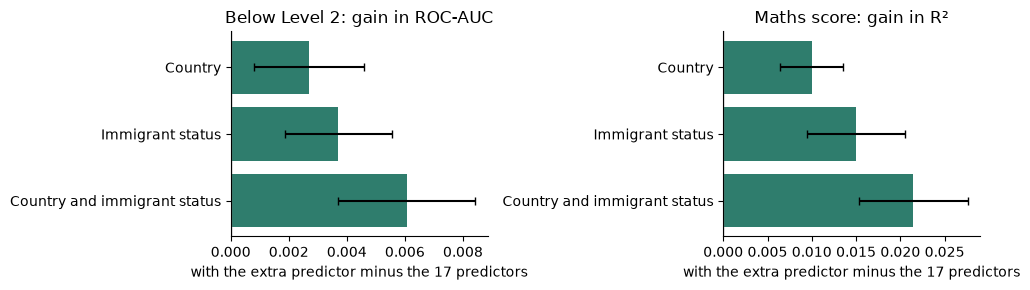

In [7]:
TITLES = {"roc_auc": "Below Level 2: gain in ROC-AUC", "r2": "Maths score: gain in R²"}
NAMES = {"country": "Country", "immigrant status": "Immigrant status", "both": "Country and immigrant status"}
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, metric in zip(axes, ["roc_auc", "r2"]):
    d = extra[extra["metric"] == metric].set_index("added").loc[list(VARIANTS)[::-1]]
    ax.barh(d.index.map(NAMES), d["gain"], xerr=1.96 * d["se"], color="#2F7D6D", capsize=3)
    ax.axvline(0, color="grey", lw=1)
    ax.set_title(TITLES[metric])
    ax.set_xlabel("with the extra predictor minus the 17 predictors")
fig.tight_layout()
fig.savefig(FIGS / "ahmed_extra_predictors.png", bbox_inches="tight", dpi=150)
plt.show()

> **Note:** bars whose interval stays clear of zero are the gains above about 2 se: all six, every variant in both panels. Both together add 0.0061 ROC-AUC and 0.0215 R². For scale, in `ahmed_ablations.ipynb` dropping the classroom group costs 0.003 ROC-AUC and 0.010 R², and dropping family costs 0.019 and 0.038.

# 5) A fairer flag inside each system
In the main notebook the 0.5 cut-off was lopsided inside systems: in MAR, PSE and JOR the model caught 0.88 or more of the students below Level 2 but correctly left out only 0.37 to 0.48 of those above it, while in ARE it caught only 0.59 of those below. The class weights balance below and above Level 2 over the pooled data, and the share below Level 2 is very different from one system to the next. So we compare three classifiers, all on the 10 PVs:

- **current**: the 17-predictor model from section 3, classes balanced over the pooled data
- **per system**: 17 predictors, classes balanced inside each system: every system keeps its `SENWT` total, split half to students below Level 2 and half to those above
- **per system + country**: the same, with `CNT` added as a predictor

The current model reuses the test predictions from section 3, so only the other two are fitted here. We score the pooled ROC-AUC with `SENWT` and, inside each system, recall for both classes, balanced accuracy and ROC-AUC with `W_FSTUWT`, as in the main notebook.

In [8]:
FLAGS = {"current": base["classification"],
         "per system": run("classification", FEATURES, PVS, balance_by_system=True),
         "per system + country": run("classification", FEATURES + ["CNT"], PVS, balance_by_system=True)}


def flag_scores(y, p, sw):
    return {"recall_below": recall_score(y, p > 0.5, pos_label=1, sample_weight=sw),
            "recall_above": recall_score(y, p > 0.5, pos_label=0, sample_weight=sw),
            "balanced_acc": balanced_accuracy_score(y, p > 0.5, sample_weight=sw),
            "roc_auc": roc_auc_score(y, p, sample_weight=sw)}


rows = []
for variant, (_, preds) in FLAGS.items():
    for pv in PVS:
        y = target("classification", pv)
        for k in range(5):
            for cnt in SYSTEMS:
                m = (df["fold"] == k) & (df["CNT"] == cnt)
                rows.append({"variant": variant, "system": cnt, "pv": pv, "fold": k,
                             **flag_scores(y[m], preds[pv][m], df.loc[m, "W_FSTUWT"])})
per_fold = pd.DataFrame(rows)

flag = []
for (variant, cnt), d in per_fold.groupby(["variant", "system"]):
    r = rubin(d.drop(columns=["variant", "system"]))
    flag.append(r.rename_axis("metric").reset_index().assign(variant=variant, system=cnt))
for variant, (res, _) in FLAGS.items():
    r = rubin(res).loc[["roc_auc"]]
    flag.append(r.rename_axis("metric").reset_index().assign(variant=variant, system="pooled"))
flag = pd.concat(flag)[["variant", "system", "metric", "score", "se"]]
flag.to_csv(OUT / "ahmed_flag_by_system.csv", index=False)

table = flag.set_index(["variant", "system", "metric"]).unstack("metric")
table = table.reindex(pd.MultiIndex.from_product([FLAGS, SYSTEMS + ["pooled"]], names=["variant", "system"]))
table[[(v, m) for v in ["score", "se"] for m in ["recall_below", "recall_above", "balanced_acc", "roc_auc"]]].round(3)

score                                    \
metric                      recall_below recall_above balanced_acc roc_auc   
variant              system                                                  
current              ARE           0.590        0.857        0.724   0.824   
                     SAU           0.767        0.553        0.660   0.726   
                     QAT           0.702        0.765        0.733   0.814   
                     JOR           0.880        0.475        0.678   0.771   
                     MAR           0.937        0.372        0.655   0.809   
                     PSE           0.924        0.399        0.662   0.783   
                     pooled          NaN          NaN          NaN   0.819   
per system           ARE           0.631        0.820        0.726   0.820   
                     SAU           0.680        0.649        0.665   0.721   
                     QAT           0.740        0.742        0.741   0.818   
                     JOR           0.754        0.644        0.699   0.771   
                     MAR           0.843        0.565        0.704   0.801   
                     PSE           0.792        0.623        0.707   0.781   
                     pooled          NaN          NaN          NaN   0.807   
per system + country ARE           0.736        0.748        0.742   0.825   
                     SAU           0.680        0.655        0.668   0.726   
                     QAT           0.769        0.715        0.742   0.818   
                     JOR           0.749        0.661        0.705   0.774   
                     MAR           0.795        0.652        0.723   0.808   
                     PSE           0.761        0.666        0.713   0.783   
                     pooled          NaN          NaN          NaN   0.801   

                                      se                                    
metric                      recall_below recall_above balanced_acc roc_auc  
variant              system                                                 
current              ARE           0.017        0.007        0.007   0.006  
                     SAU           0.013        0.021        0.008   0.007  
                     QAT           0.021        0.015        0.012   0.013  
                     JOR           0.009        0.023        0.012   0.014  
                     MAR           0.009        0.047        0.021   0.015  
                     PSE           0.007        0.030        0.013   0.013  
                     pooled          NaN          NaN          NaN   0.004  
per system           ARE           0.014        0.008        0.005   0.005  
                     SAU           0.012        0.019        0.009   0.008  
                     QAT           0.020        0.017        0.010   0.013  
                     JOR           0.011        0.022        0.011   0.013  
                     MAR           0.014        0.038        0.016   0.013  
                     PSE           0.009        0.026        0.013   0.012  
                     pooled          NaN          NaN          NaN   0.003  
per system + country ARE           0.015        0.012        0.005   0.005  
                     SAU           0.012        0.016        0.006   0.007  
                     QAT           0.017        0.016        0.011   0.013  
                     JOR           0.015        0.017        0.011   0.013  
                     MAR           0.016        0.040        0.015   0.014  
                     PSE           0.010        0.024        0.011   0.013  
                     pooled          NaN          NaN          NaN   0.004

> **Note:** with the current model the 0.5 cut-off flags most students in MAR, PSE and JOR (recall below 0.94, 0.92 and 0.88, recall above only 0.37, 0.40 and 0.48) and misses many students below Level 2 in ARE (recall below 0.59). Balanced inside each system and with country, the two recalls are at most 0.14 apart in every system. The per-system ROC-AUC hardly moves between the three (by at most 0.008), so the better flag comes from where the 0.5 cut-off falls inside each system, not from a better ranking of students. The pooled ROC-AUC goes the other way: 0.819 (se 0.004) for the current model, 0.807 (se 0.003) balanced per system and 0.801 (se 0.004) with country as well. Each score has its own se, so we compare each gap with √(se1² + se2²). The drop to 0.801 is about 3 times that, so it is clear. The drop to 0.807 is about 2 times, and 0.807 against 0.801 is within the noise.

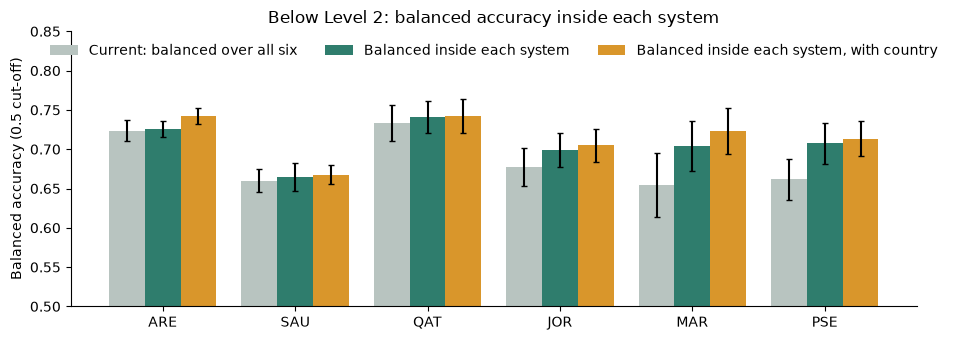

In [9]:
LABELS = {"current": "Current: balanced over all six", "per system": "Balanced inside each system",
          "per system + country": "Balanced inside each system, with country"}
COLORS = {"current": "#B8C4C0", "per system": "#2F7D6D", "per system + country": "#D9962B"}
x = np.arange(len(SYSTEMS))
fig, ax = plt.subplots(figsize=(10, 3.5))
for i, variant in enumerate(FLAGS):
    d = flag[(flag["variant"] == variant) & (flag["metric"] == "balanced_acc")].set_index("system").loc[SYSTEMS]
    ax.bar(x + (i - 1) * 0.27, d["score"], width=0.27, yerr=1.96 * d["se"], color=COLORS[variant],
           capsize=2, label=LABELS[variant])
ax.set_xticks(x, SYSTEMS)
ax.set_ylim(0.5, 0.85)
ax.set_ylabel("Balanced accuracy (0.5 cut-off)")
ax.set_title("Below Level 2: balanced accuracy inside each system")
ax.legend(frameon=False, ncol=3, loc="upper center")
fig.tight_layout()
fig.savefig(FIGS / "ahmed_flag_by_system.png", bbox_inches="tight", dpi=150)
plt.show()

> **Note:** balancing inside each system lifts balanced accuracy most where the current cut-off was most lopsided: MAR goes from 0.655 to 0.723 (with country), PSE from 0.662 to 0.713 and JOR from 0.678 to 0.705. Each score has its own se and the table has no se for the difference, so we only call a rise clear if it is more than 2 × √(se1² + se2²). MAR and PSE pass that. JOR goes the same way but by less, so we only read the direction. In ARE it only goes up once country is added (0.724 current, 0.726 per system, 0.742 with country, a rise of about 2 se), probably because without country the model can only partly tell which system a student is in, so the cut-off for ARE moves only a little (recall below 0.59 to 0.63). With country the recall below goes to 0.74. In SAU and QAT it moves less (0.660 to 0.668 and 0.733 to 0.742), within the noise.

# 6) Summary

- We added country (`CNT`), immigrant status (`IMMIG`) or both to the 17 predictors of the tuned gradient boosting, and compared each with the 17-predictor model on the same 10 PVs and 5 school folds. The gains are in `outputs/ahmed_extra_predictors.csv` and the figure in section 4.
- Country: ROC-AUC up 0.0027 (se 0.0010), R² up 0.0100 (se 0.0018). Immigrant status: ROC-AUC up 0.0037 (se 0.0009), R² up 0.0150 (se 0.0028). Both: ROC-AUC up 0.0061 (se 0.0012), R² up 0.0215 (se 0.0031). Taking a gain as clear only above about 2 se, all six gains are clear. Even the smallest, country on ROC-AUC, is more than 2 se.
- Short answer for the team's two decisions: country and immigrant status both help, and all six gains above are clear (more than 2 se), but they are small. Both together add 0.0061 ROC-AUC and 0.0215 R², less than dropping family takes away (0.019 ROC-AUC and 0.038 R²). Whether that is worth the costs below is for the team to decide. With country the model learns where each system sits rather than anything about students or schools, and it can only be used on these six systems. Immigrant status mostly varies in ARE and QAT, so most of its gain should come from there (we did not measure the gain per system). If the team adds either one, every model has to be rerun with it so the results still compare. Our main notebooks stay on the 17 predictors.
- A fairer flag (section 5, `outputs/ahmed_flag_by_system.csv`): balancing the classes inside each system, with country, brings the two recalls much closer where they were far apart. They are at most 0.14 apart in every system, against more than 0.5 in MAR and PSE for the current model. Balanced accuracy goes up clearly in MAR and PSE, by about 2 se in ARE, and in JOR, SAU and QAT it goes the same way but within the noise. But the pooled ROC-AUC drops from 0.819 to 0.801 (se 0.004 each, a clear drop). With the weights every system is about half below and half above Level 2, so the model stops using the differences between systems to rank students, and those differences are part of what the pooled ROC-AUC rewards. Which flag is better depends on the use: one ranking across all six systems, or a cut-off that works the same inside each one.

Next: take these numbers to the team for the two open decisions in `NEXT_STEPS.md`.